# Does Education Level Affect Employment Status?

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [18]:
education_level = np.array(["Matric","intermediate","bachelor","Master"])
employed = np.array([45,70,100,90])
unemployed = np.array([55,35,30,15])
self_employed = np.array([20,25,40,35])
observed_df = pd.DataFrame(
    {
        "Education_level":education_level,
        "Employed":employed,
        "Unemployed":unemployed,
        "Self_employed":self_employed
    }
)
observed_df

,Education_level,Employed,Unemployed,Self_employed
0,Matric,45,55,20
1,intermediate,70,35,25
2,bachelor,100,30,40
3,Master,90,15,35


In [19]:
observed =observed_df[["Employed","Unemployed","Self_employed"]]
row_wise_sum = observed.sum(axis=1)
column_wise_sum = observed.sum(axis=0)
total = observed.sum().sum()
print("row wise sum : \n",row_wise_sum)
print("\ncolumn wise sum : \n",column_wise_sum)
print("\ntotal student : ",total)



row wise sum : 
 0    120
1    130
2    170
3    140
dtype: int64

column wise sum : 
 Employed         305
Unemployed       135
Self_employed    120
dtype: int64

total student :  560


In [20]:
expected = np.outer(row_wise_sum,column_wise_sum/total)
expected_Df = pd.DataFrame(expected,index=education_level,columns=observed.columns)
expected_Df

,Employed,Unemployed,Self_employed
Matric,65.357143,28.928571,25.714286
intermediate,70.803571,31.339286,27.857143
bachelor,92.589286,40.982143,36.428571
Master,76.250000,33.750000,30.000000


In [21]:
from scipy.stats import chi2_contingency
chi_square_Stats,p_value,Dof,expected_freq = chi2_contingency(observed)
print("chi square stats : ",chi_square_Stats)
print("p Value :",p_value)
print("Dof : ",Dof)
print("Expected frequency : ",expected_freq)


chi square stats :  49.452546840042835
p Value : 6.051950375189396e-09
Dof :  6
Expected frequency :  [[65.35714286 28.92857143 25.71428571]
 [70.80357143 31.33928571 27.85714286]
 [92.58928571 40.98214286 36.42857143]
 [76.25       33.75       30.        ]]


In [22]:
alpha = 0.05
if p_value < alpha :
    print("Decision : we reject the null hypothesis .")
else:
    print("Decision : we are fail to reject the null hypothesis.")

Decision : we reject the null hypothesis .


<Figure size 800x900 with 0 Axes>

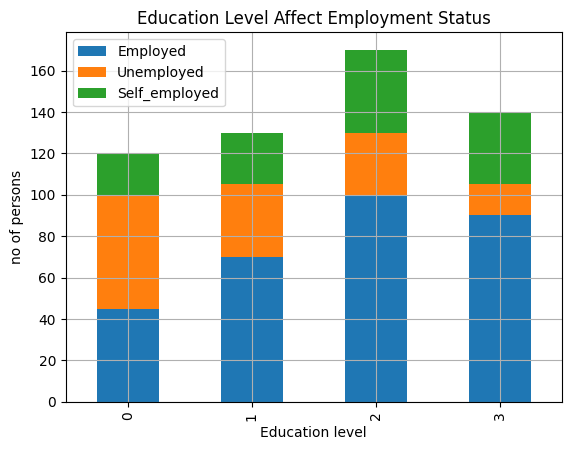

In [29]:
x  = np.arange(len(observed))
plt.figure(figsize=(8,9))
width = 0.35
observed_df.plot(kind="bar",stacked=True)
plt.title("Education Level Affect Employment Status")
plt.xlabel("Education level")
plt.ylabel("no of persons")
plt.grid()
plt.show()